# Destilação vs. treino direto — pipeline passo a passo

Cada célula chama as funções de `src/` com os valores de `src/config.py`. Tudo é cacheado:
rodar uma célula de novo pula o que já terminou, e um treino interrompido retoma da última época.

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from IPython.display import Image, display
from src import config as C
from src.common import DEVICE, AMP_DTYPE
from src.report import CLASSES
from src.data import make_splits, load_split
from src.data import make_views
from src.extract import extract
from src.probe import select, run, HP_PATH
from src.train import train
from src.report import fig_projection
from src import cost
from src.extract import all_encoders
from src.report import run as report

SIZE = "S"          # aluno usado nas seções 4-8 ("S" ou "L")
SEED = 0
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))

%load_ext autoreload
%autoreload 2


print(f"raiz {C.ROOT} | device {DEVICE} ({AMP_DTYPE})")
print(f"não rotuladas {C.N_UNLABELED} | K {C.K_VIEWS} | épocas {C.EPOCHS} (warm-up {C.WARMUP_EPOCHS}) "
      f"| batch {C.BATCH} | {C.IMG_SIZE}px | pool dos probes {C.PROBE_POOL or 'treino inteiro'}")
print(f"alunos {C.SIZES} | seeds {C.SEEDS}")

raiz /home/kdunorat/Projetos/distillation-unsupervised | device cuda (torch.bfloat16)
não rotuladas 89996 | K 8 | épocas 40 (warm-up 4) | batch 256 | 64px | pool dos probes treino inteiro
alunos {'S': 0.5, 'L': 1.5} | seeds {'S': [0, 1, 2], 'L': [0, 1]}


## 1. Dados e splits fixos

In [2]:
make_splits()          # determinístico: rodar de novo gera exatamente os mesmos arquivos
x_tr, y_tr = load_split("train")
x_te, y_te = load_split("test")


fig, ax = plt.subplots(figsize=(8, 3))
w = 0.4
ax.bar(np.arange(9) - w/2, np.bincount(y_tr) / len(y_tr), w, label="train", color="#2a78d6")
ax.bar(np.arange(9) + w/2, np.bincount(y_te) / len(y_te), w, label="test", color="#eb6834")
ax.set_xticks(range(9), CLASSES, rotation=30, ha="right"); ax.set_ylabel("fração"); ax.legend()
plt.tight_layout(); plt.show()

[data] converting pathmnist_128.npz:train -> .npy (one-off)
[data] converting pathmnist_128.npz:test -> .npy (one-off)
[data] train 89996  test 7180
[data] train class counts [9366, 9509, 10360, 10401, 8006, 12182, 7886, 9401, 12885]
[data] test  class counts [1338, 847, 339, 634, 1035, 592, 741, 421, 1233]
{
  "n_train": 89996,
  "n_test": 7180,
  "n_unlabeled": 89996,
  "probe_pool": 89996,
  "label_subset_sizes": {
    "0.01": 899,
    "0.1": 8999,
    "0.5": 44998,
    "1.0": 89996
  }
}


/tmp/ipykernel_254245/4165160733.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


In [3]:
# 6 examples per class (native 128 px)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(9, 6, figsize=(7, 11))
for c in range(9):
    for j, i in enumerate(rng.choice(np.where(y_tr == c)[0], 6, replace=False)):
        axes[c, j].imshow(x_tr[i]); axes[c, j].axis("off")
    axes[c, 0].set_title(CLASSES[c], fontsize=8, loc="left")
plt.tight_layout(); plt.show()

/tmp/ipykernel_254245/2748907985.py:8: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


## 2. Views aumentadas + features do professor (cache)
K views por imagem, geradas uma vez (lightly `VICRegViewTransform` a 128 px). O aluno usa a view
reduzida para 64 px; o professor, a mesma view ampliada para 224 px. Pulado se o cache já existe.

In [4]:
if not (C.CACHE / "views_meta.json").exists():
    make_views(batch=32, workers=8)
print(json.loads((C.CACHE / "views_meta.json").read_text()))

[views] 89996/89996 images  (917s)
{
  "n": 89996,
  "k": 8,
  "img_size": 64,
  "view_size": 128,
  "teacher": "vit_small_patch16_224.dino",
  "teacher_dim": 384,
  "teacher_forward_gpu_hours": 0.24818379627333748,
  "total_seconds": 917.1171176433563,
  "device": "cuda",
  "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU"
}
{'n': 89996, 'k': 8, 'img_size': 64, 'view_size': 128, 'teacher': 'vit_small_patch16_224.dino', 'teacher_dim': 384, 'teacher_forward_gpu_hours': 0.24818379627333748, 'total_seconds': 917.1171176433563, 'device': 'cuda', 'gpu': 'NVIDIA GeForce RTX 3050 Laptop GPU'}


In [8]:
# checking augmentations
views = np.load(C.CACHE / f"views_{C.IMG_SIZE}.npy", mmap_mode="r")
unl = np.load(C.SPLITS / "unlabeled_idx.npy")
n_show, K = 5, views.shape[1]
fig, axes = plt.subplots(n_show, K + 1, figsize=(1.6 * (K + 1), 1.7 * n_show))
for r in range(n_show):
    axes[r, 0].imshow(x_tr[unl[r]]); axes[r, 0].set_title(CLASSES[y_tr[unl[r]]], fontsize=7)
    for k in range(K):
        axes[r, k + 1].imshow(views[r, k].transpose(1, 2, 0))
for a in axes.flat: a.axis("off")
plt.tight_layout()
plt.show()

/tmp/ipykernel_254245/186644123.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 3. Linha D — professor (checagem de sanidade)
k-NN bem acima do acaso (~11% com 9 classes; a coluna `chance` mostra a classe majoritária),
`emb_std` claramente > 0 e NMI > 0. Se falhar aqui, pare e investigue antes de treinar.

In [6]:
from src.extract import extract
extract("D")
pd.Series(json.loads((C.RESULTS / "sanity_D.json").read_text()))

[extract] D cached


knn_acc             0.948329
chance              0.186351
emb_std             0.037068
emb_std_x_sqrt_d    0.726380
kmeans_nmi          0.869109
kmeans_ari          0.838968
dtype: float64

## 4. Linha A — aluno com pesos aleatórios (mesma inicialização da seed em B e C)

In [9]:
extract("A", SIZE, SEED)
pd.Series(json.loads((C.RESULTS / f"sanity_{C.tag('A', SIZE, SEED)}.json").read_text()))

[extract] A_S_s0: train (89996, 128) test (7180, 128) -> A_S_s0.npz
[sanity] A_S_s0: {"knn_acc": 0.46852367688022284, "chance": 0.18635097493036212, "emb_std": 0.0066454121842980385, "emb_std_x_sqrt_d": 0.0751842563087496, "kmeans_nmi": 0.38839693166260897, "kmeans_ari": 0.2942198661381588}


knn_acc             0.468524
chance              0.186351
emb_std             0.006645
emb_std_x_sqrt_d    0.075184
kmeans_nmi          0.388397
kmeans_ari          0.294220
dtype: float64

## 5. Linhas B e C — treino
Mesma arquitetura, inicialização, views, épocas, passos, batch, otimizador e schedule; só o objetivo muda.
O progresso aparece abaixo; se interromper, rodar a célula de novo retoma da última época.

In [2]:
def plot_log(tags):
    # uma painel de loss por run (B e C têm escalas diferentes), depois k-NN e std
    fig, axes = plt.subplots(1, len(tags) + 2, figsize=(4.2 * (len(tags) + 2), 3.2))
    for i, t in enumerate(tags):
        p = C.RUNS / t / "log.csv"
        if not p.exists(): continue
        d = pd.read_csv(p)
        axes[i].plot(d.epoch, d.loss, marker=".", color=f"C{i}")
        axes[i].set_title(f"loss {t}", fontsize=10)
        m = d.dropna(subset=["knn_acc"])
        axes[-2].plot(m.epoch, 100 * m.knn_acc, marker="o", color=f"C{i}", label=t)
        axes[-1].plot(m.epoch, m.emb_std_x_sqrt_d, marker="o", color=f"C{i}", label=t)
    axes[-2].set_title("k-NN no conjunto diag (%)", fontsize=10)
    axes[-1].set_title("std por dim × √d  (→0 = colapso)", fontsize=10)
    for a in axes: a.set_xlabel("época"); a.grid(alpha=.3)
    axes[-1].legend(fontsize=8); plt.tight_layout(); plt.show()

TAG_B, TAG_C = C.tag("B", SIZE, SEED), C.tag("C", SIZE, SEED)

{
 "name": "B_S_s0_d100",
 "row": "B",
 "size": "S",
 "seed": 0,
 "data_frac": 1.0,
 "n_unlabeled": 89996,
 "k_views": 8,
 "epochs": 40,
 "batch": 256,
 "lr": 0.001,
 "wd": 0.05,
 "steps_per_epoch": 351,
 "total_steps": 14040,
 "img_size": 64,
 "params_backbone": 700176,
 "params_head": 8665088,
 "feat_dim": 128,
 "device": "cuda",
 "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU"
}
[B_S_s0_d100] ep 1/40 step 350/351 loss 21.4855
[B_S_s0_d100] ep 2/40 step 350/351 loss 21.1485
[B_S_s0_d100] ep 3/40 step 350/351 loss 20.6358
[B_S_s0_d100] ep 4/40 step 350/351 loss 20.2854
[B_S_s0_d100] ep 5/40 step 350/351 loss 19.7428
[B_S_s0_d100] ep 6/40 step 350/351 loss 19.6338
[B_S_s0_d100] ep 7/40 step 350/351 loss 19.2667
[B_S_s0_d100] ep 8/40 step 350/351 loss 19.4320
[B_S_s0_d100] ep 9/40 step 350/351 loss 19.2821
[B_S_s0_d100] ep 10/40 step 350/351 loss 19.1265
[B_S_s0_d100] collapse check: {'knn_acc': 0.803, 'chance': 0.136, 'emb_std': 0.05944352596998215, 'emb_std_x_sqrt_d': 0.6725267249762084, 

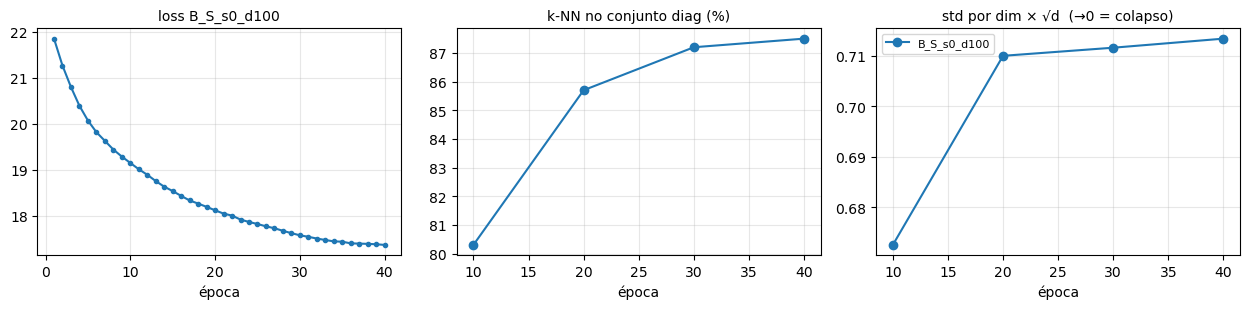

In [3]:
train("B", SIZE, SEED)
torch.cuda.empty_cache()
plot_log([TAG_B])

{
 "name": "C_S_s0_d100",
 "row": "C",
 "size": "S",
 "seed": 0,
 "data_frac": 1.0,
 "n_unlabeled": 89996,
 "k_views": 8,
 "epochs": 40,
 "batch": 256,
 "lr": 0.001,
 "wd": 0.05,
 "steps_per_epoch": 351,
 "total_steps": 14040,
 "img_size": 64,
 "params_backbone": 700176,
 "params_head": 1055104,
 "feat_dim": 128,
 "device": "cuda",
 "gpu": "NVIDIA GeForce RTX 3050 Laptop GPU"
}
[C_S_s0_d100] ep 1/40 step 350/351 loss 0.2993
[C_S_s0_d100] ep 2/40 step 350/351 loss 0.2535
[C_S_s0_d100] ep 3/40 step 350/351 loss 0.2326
[C_S_s0_d100] ep 4/40 step 350/351 loss 0.2131
[C_S_s0_d100] ep 5/40 step 350/351 loss 0.1870
[C_S_s0_d100] ep 6/40 step 350/351 loss 0.1700
[C_S_s0_d100] ep 7/40 step 350/351 loss 0.1624
[C_S_s0_d100] ep 8/40 step 350/351 loss 0.1517
[C_S_s0_d100] ep 9/40 step 350/351 loss 0.1568
[C_S_s0_d100] ep 10/40 step 350/351 loss 0.1556
[C_S_s0_d100] collapse check: {'knn_acc': 0.898, 'chance': 0.136, 'emb_std': 0.05590430274605751, 'emb_std_x_sqrt_d': 0.632484985107888, 'kmeans_nmi

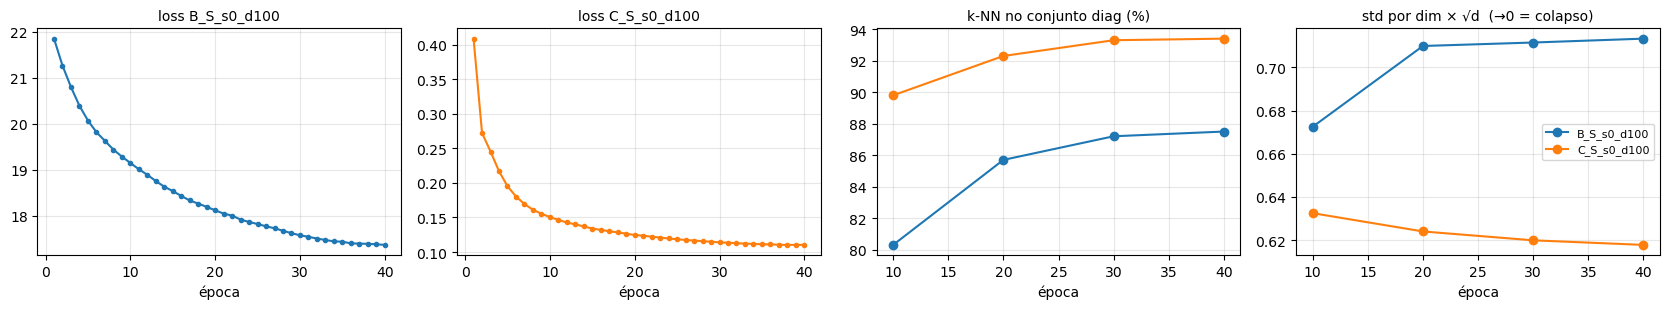

In [4]:
train("C", SIZE, SEED)
torch.cuda.empty_cache()
plot_log([TAG_B, TAG_C])

## 6. Probes (k-NN, SVM linear, SVM RBF) + k-means
C e γ das SVMs são escolhidos **uma vez** em B (100% dos rótulos, CV só no treino) e congelados.

In [7]:
for row, args in [("A", (SIZE, SEED)), ("B", (SIZE, SEED)), ("C", (SIZE, SEED))]:
    extract(row, *args)
if not HP_PATH.exists():
    select(TAG_B)
print(json.loads(HP_PATH.read_text()))
TAGS = [C.tag("A", SIZE, SEED), TAG_B, TAG_C, "D"]
for t in TAGS:
    run(t)

[extract] A_S_s0 cached


/home/kdunorat/Projetos/distillation-unsupervised/src/extract.py:35: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  sd = torch.load(C.RUNS / C.tag(row, size, seed, data_frac)

[extract] B_S_s0_d100: train (89996, 128) test (7180, 128) -> B_S_s0_d100.npz
[extract] C_S_s0_d100: train (89996, 128) test (7180, 128) -> C_S_s0_d100.npz
{
  "selected_on": "B_S_s0_d100",
  "n_cv": 10000,
  "linear_C": 0.1,
  "linear_cv_acc": 0.8993002479612088,
  "rbf_C": 1.0,
  "rbf_gamma_mult": 2.0,
  "rbf_cv_acc": 0.9090000181781827
}
{'selected_on': 'B_S_s0_d100', 'n_cv': 10000, 'linear_C': 0.1, 'linear_cv_acc': 0.8993002479612088, 'rbf_C': 1.0, 'rbf_gamma_mult': 2.0, 'rbf_cv_acc': 0.9090000181781827}
[probe] A_S_s0: linear acc by frac 0.01:0.406, 0.01:0.406, 0.01:0.412, 0.1:0.504, 0.1:0.506, 0.1:0.500, 0.5:0.526, 0.5:0.521, 0.5:0.525, 1.0:0.529 | NMI 0.403
[probe] B_S_s0_d100: linear acc by frac 0.01:0.852, 0.01:0.858, 0.01:0.863, 0.1:0.886, 0.1:0.882, 0.1:0.888, 0.5:0.888, 0.5:0.890, 0.5:0.889, 1.0:0.891 | NMI 0.778
[probe] C_S_s0_d100: linear acc by frac 0.01:0.900, 0.01:0.903, 0.01:0.906, 0.1:0.924, 0.1:0.917, 0.1:0.928, 0.5:0.924, 0.5:0.926, 0.5:0.924, 1.0:0.926 | NMI 0.839

In [8]:
df = pd.concat([pd.read_csv(C.RESULTS / "probes" / f"{t}.csv") for t in TAGS])
tab = (df.groupby(["probe", "row", "label_frac"]).acc.agg(["mean", "std"]).mul(100).round(1)
         .assign(v=lambda d: d["mean"].astype(str) + " ± " + d["std"].fillna(0).astype(str))
         .v.unstack("label_frac"))
tab.columns = [f"{int(c*100)}%" for c in tab.columns]
display(tab)
cl = pd.DataFrame([json.loads((C.RESULTS / "clusters" / f"{t}.json").read_text()) for t in TAGS])
display(cl[["tag", "feat_dim", "kmeans_nmi", "kmeans_ari"]].round(3))

1%         10%         50%        100%
probe  row                                                
knn    A    38.1 ± 2.7  44.9 ± 0.1  48.4 ± 0.9  50.3 ± 0.0
       B    88.8 ± 0.2  88.8 ± 0.3  88.8 ± 0.1  88.6 ± 0.0
       C    89.6 ± 0.0  91.4 ± 0.1  91.5 ± 0.1  91.6 ± 0.0
       D    92.0 ± 0.6  93.9 ± 0.2  94.5 ± 0.1  94.7 ± 0.0
linear A    40.8 ± 0.3  50.3 ± 0.3  52.4 ± 0.3  52.9 ± 0.0
       B    85.8 ± 0.6  88.5 ± 0.3  88.9 ± 0.1  89.1 ± 0.0
       C    90.3 ± 0.3  92.3 ± 0.5  92.5 ± 0.1  92.6 ± 0.0
       D    91.3 ± 0.9  92.3 ± 0.4  94.1 ± 0.1  94.7 ± 0.0
rbf    A    46.8 ± 0.1  54.8 ± 1.2  55.2 ± 0.5  56.2 ± 0.0
       B    88.4 ± 0.6  88.9 ± 0.5  89.3 ± 0.6  88.6 ± 0.0
       C    90.1 ± 0.7  92.1 ± 0.3  92.0 ± 0.2  92.2 ± 0.0
       D    91.3 ± 0.4  95.1 ± 0.1  95.5 ± 0.1  95.3 ± 0.0

,tag,feat_dim,kmeans_nmi,kmeans_ari
0,A_S_s0,128,0.403,0.315
1,B_S_s0_d100,128,0.778,0.721
2,C_S_s0_d100,128,0.839,0.811
3,D,384,0.870,0.837


## 7. Projeção 2-D (UMAP, mesmos parâmetros para os quatro encoders)

I0000 00:00:1795466981.704900  261467 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795466983.869158  261467 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795466985.913443  261467 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 b

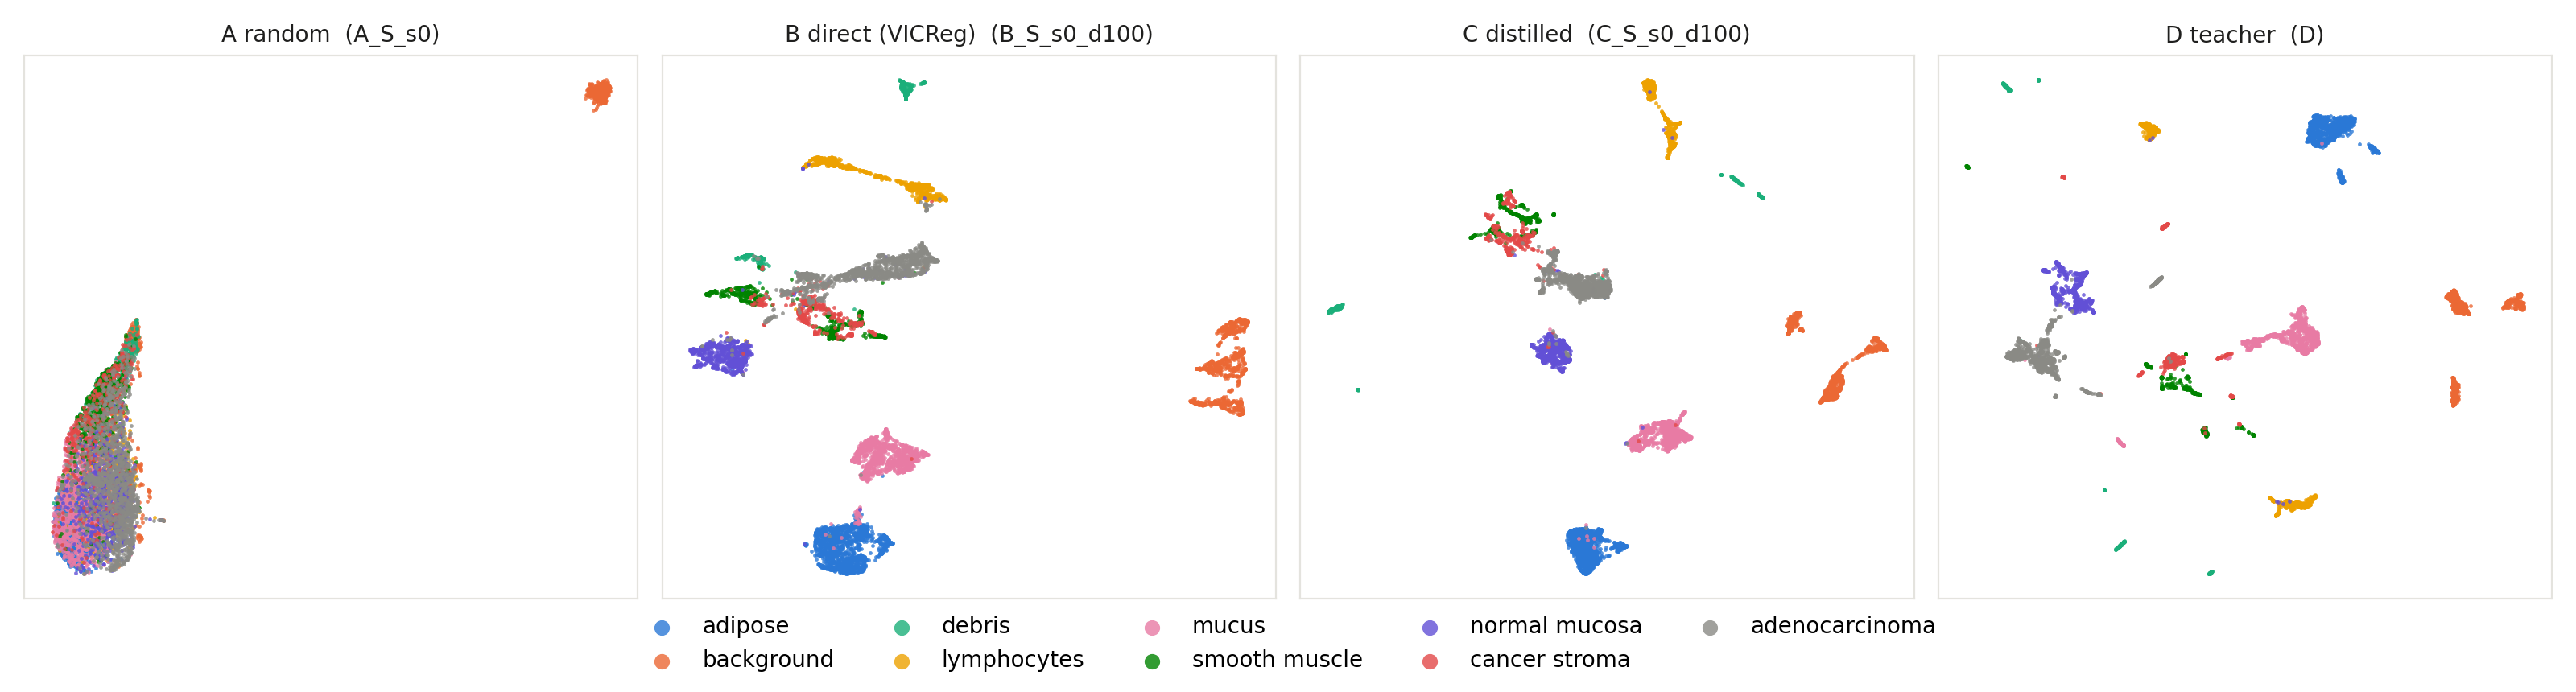

In [9]:
from src.report import fig_projection
fig_projection(SIZE, SEED, "umap")
display(Image(str(C.FIGS / f"projection_{SIZE}.png")))

## 8. Custo: parâmetros, FLOPs, latência, horas de GPU

In [10]:
cost.main()

  encoder  input_size  params_M  gflops_per_image  feat_dim  latency_ms_batch128  throughput_img_s                             device            amp
student_S          64  0.700176          0.070091       128             2.928633      43706.397576 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
student_L          64  6.284592          0.625508       384            11.365564      11262.089371 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
  teacher         224 21.665664          9.196997       384           141.569510        904.149490 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
                 name       row size  seed  data_frac  epochs  total_steps  train_gpu_hours
          B_S_s0_d100         B    S   0.0        1.0    40.0      14040.0         0.363588
          C_S_s0_d100         C    S   0.0        1.0    40.0      14040.0         0.093685
teacher_forward_cache C(shared)  NaN   NaN        NaN     NaN          NaN         0.248184


## 9. Estudo completo
Roda tudo que falta (principal primeiro, ablação depois), pulando o que já terminou.

In [2]:
for frac in C.DATA_FRACS:                      # 1.0 (principal) e 0.5 (ablação)
    for size, seeds in C.SEEDS.items():
        for s in seeds:
            for row in ("B", "C"):
                train(row, size, s, frac); torch.cuda.empty_cache()

for j in all_encoders():
    extract(*j)
if not HP_PATH.exists():
    select(C.tag("B", "S", 0))
for p in sorted(C.FEATS.glob("*.npz")):
    run(p.stem)
cost.main()

[B_S_s0_d100] already finished, skipping
[C_S_s0_d100] already finished, skipping
[B_S_s1_d100] already finished, skipping
[C_S_s1_d100] already finished, skipping
[B_S_s2_d100] already finished, skipping
[C_S_s2_d100] already finished, skipping
[B_L_s0_d100] already finished, skipping
[C_L_s0_d100] already finished, skipping
[B_L_s1_d100] already finished, skipping
[C_L_s1_d100] already finished, skipping
[B_S_s0_d50] already finished, skipping
[C_S_s0_d50] already finished, skipping
[B_S_s1_d50] already finished, skipping
[C_S_s1_d50] already finished, skipping
[B_S_s2_d50] already finished, skipping
[C_S_s2_d50] already finished, skipping
[B_L_s0_d50] already finished, skipping
[C_L_s0_d50] already finished, skipping
[B_L_s1_d50] already finished, skipping
[C_L_s1_d50] already finished, skipping
[extract] D cached
[extract] A_S_s0 cached
[extract] A_S_s1 cached
[extract] A_S_s2 cached
[extract] A_L_s0 cached
[extract] A_L_s1 cached
[extract] A_M_s0: train (89996, 256) test (7180, 25

   encoder  input_size  params_M  gflops_per_image  feat_dim  latency_ms_batch128  throughput_img_s                             device            amp
 student_S          64  0.700176          0.070091       128             2.974102      43038.201399 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
 student_L          64  6.284592          0.625508       384            11.394152      11233.832521 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
 student_M          64  2.795040          0.278594       256             5.546919      23075.872959 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
student_XL          64  9.127016          0.879567       464            16.973227       7541.288371 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
   teacher         224 21.665664          9.196997       384           142.367881        899.079199 NVIDIA GeForce RTX 3050 Laptop GPU torch.bfloat16
                 name       row size  seed  data_frac  epochs  total_steps  train_gpu_hours
        


### linear probe accuracy (%), mean ± std over seeds × draws

| row   | size   | 1%         | 10%        | 50%        | 100%       |
|:------|:-------|:-----------|:-----------|:-----------|:-----------|
| A     | L      | 42.9 ± 1.5 | 60.0 ± 1.7 | 65.0 ± 1.6 | 65.4 ± 2.1 |
| A     | M      | 41.1 ± 2.3 | 56.0 ± 0.5 | 60.1 ± 0.6 | 60.6 ± 0.5 |
| A     | S      | 44.0 ± 2.6 | 53.2 ± 2.2 | 55.2 ± 2.4 | 55.5 ± 2.7 |
| A     | XL     | 42.8 ± 1.0 | 58.9 ± 1.5 | 64.3 ± 1.3 | 64.6 ± 1.0 |
| B     | L      | 89.7 ± 0.7 | 90.1 ± 0.4 | 91.2 ± 0.1 | 91.4 ± 0.4 |
| B     | S      | 86.2 ± 0.7 | 88.2 ± 0.3 | 88.9 ± 0.1 | 89.1 ± 0.1 |
| C     | L      | 92.5 ± 0.8 | 93.2 ± 0.3 | 94.4 ± 0.3 | 94.7 ± 0.2 |
| C     | S      | 89.9 ± 0.4 | 91.5 ± 0.8 | 91.8 ± 0.7 | 91.9 ± 0.7 |
| D     | -      | 91.3 ± 0.9 | 92.3 ± 0.4 | 94.1 ± 0.1 | 94.7 ± 0.0 |

### rbf probe accuracy (%), mean ± std over seeds × draws

| row   | size   | 1%         | 10%        | 50%        | 100%       |
|:------|:-------|:------

/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/kdunorat/miniconda3/envs/mestrado/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


[report] figures in /home/kdunorat/Projetos/distillation-unsupervised/figures

### linear probe accuracy (%), mean ± std over seeds × draws

| row   | size   | 1%         | 10%        | 50%        | 100%       |
|:------|:-------|:-----------|:-----------|:-----------|:-----------|
| A     | L      | 42.9 ± 1.5 | 60.0 ± 1.7 | 65.0 ± 1.6 | 65.4 ± 2.1 |
| A     | M      | 41.1 ± 2.3 | 56.0 ± 0.5 | 60.1 ± 0.6 | 60.6 ± 0.5 |
| A     | S      | 44.0 ± 2.6 | 53.2 ± 2.2 | 55.2 ± 2.4 | 55.5 ± 2.7 |
| A     | XL     | 42.8 ± 1.0 | 58.9 ± 1.5 | 64.3 ± 1.3 | 64.6 ± 1.0 |
| B     | L      | 89.7 ± 0.7 | 90.1 ± 0.4 | 91.2 ± 0.1 | 91.4 ± 0.4 |
| B     | S      | 86.2 ± 0.7 | 88.2 ± 0.3 | 88.9 ± 0.1 | 89.1 ± 0.1 |
| C     | L      | 92.5 ± 0.8 | 93.2 ± 0.3 | 94.4 ± 0.3 | 94.7 ± 0.2 |
| C     | S      | 89.9 ± 0.4 | 91.5 ± 0.8 | 91.8 ± 0.7 | 91.9 ± 0.7 |
| D     | -      | 91.3 ± 0.9 | 92.3 ± 0.4 | 94.1 ± 0.1 | 94.7 ± 0.0 |

### rbf probe accuracy (%), mean ± std over seeds × draws

| row   | size   |

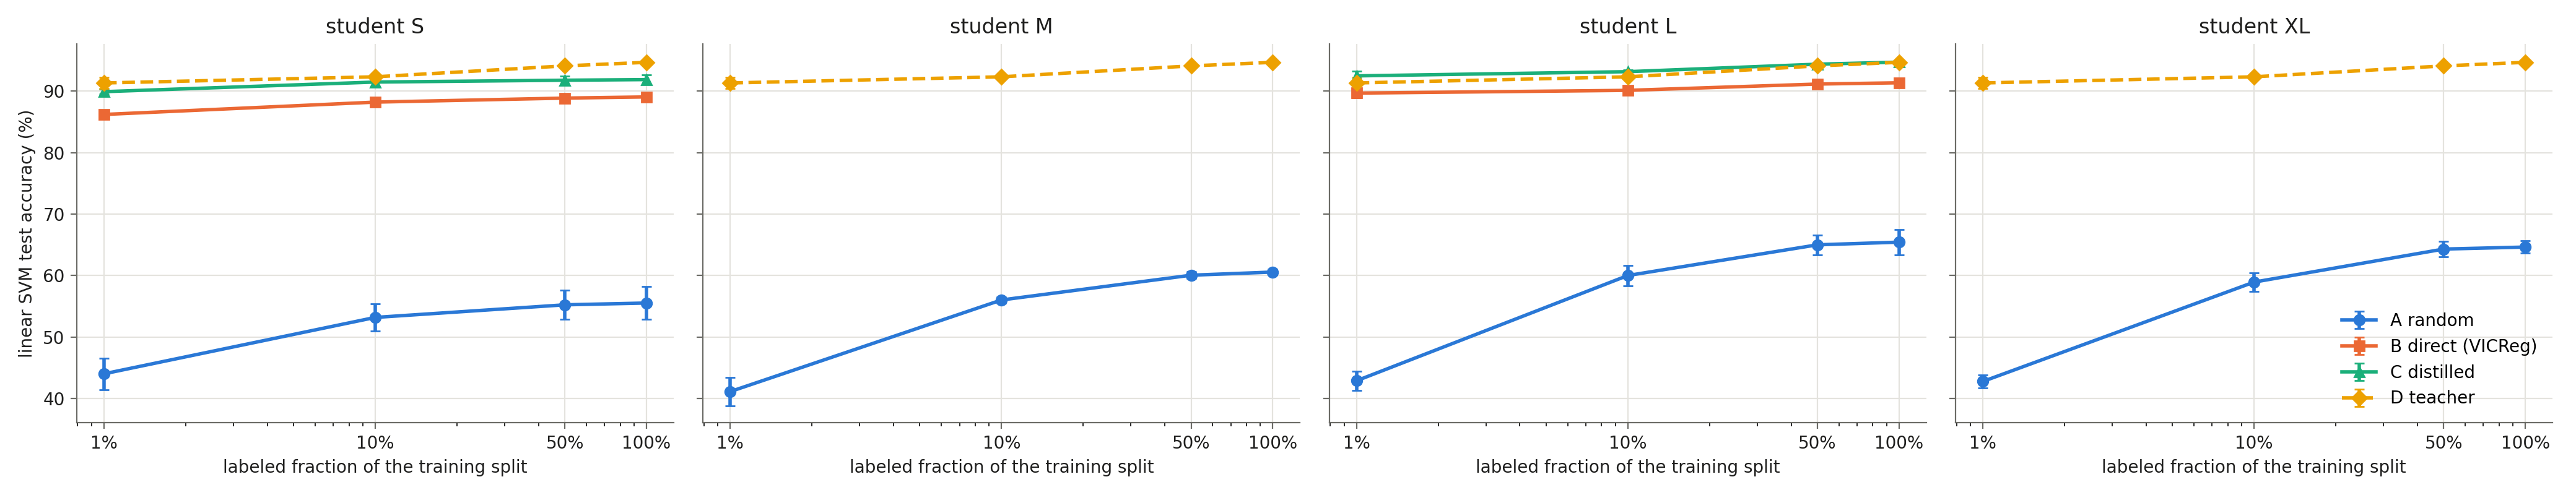

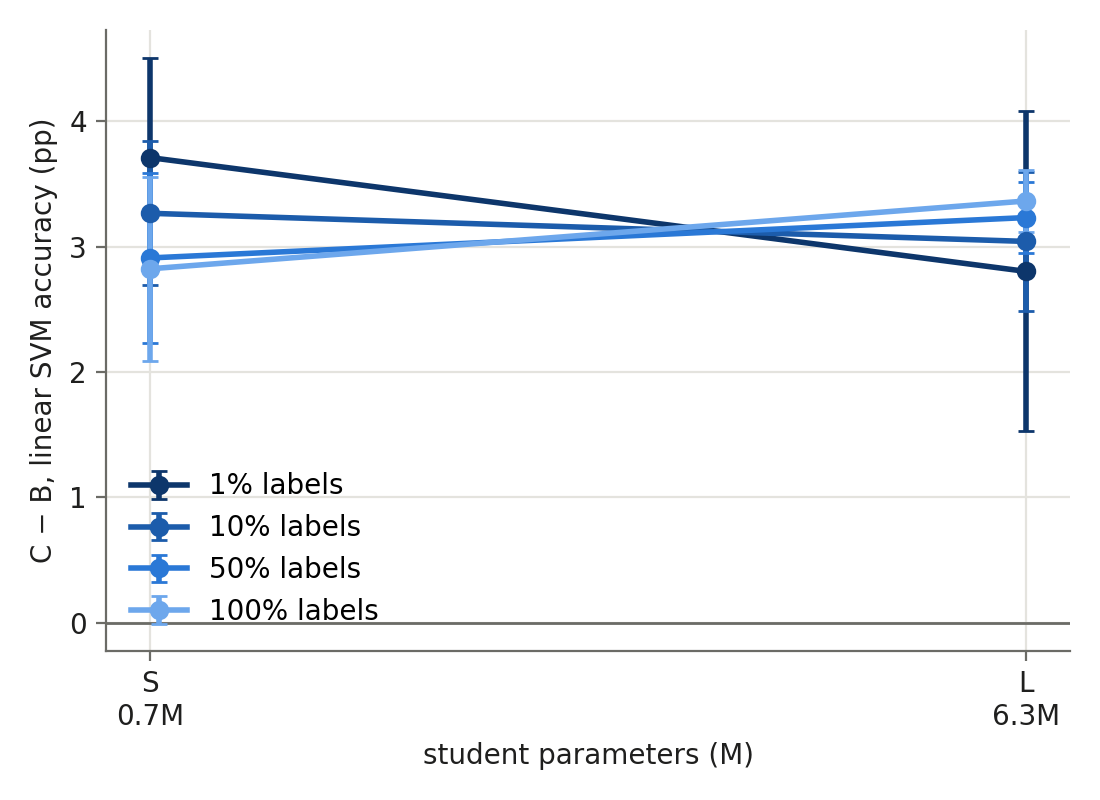

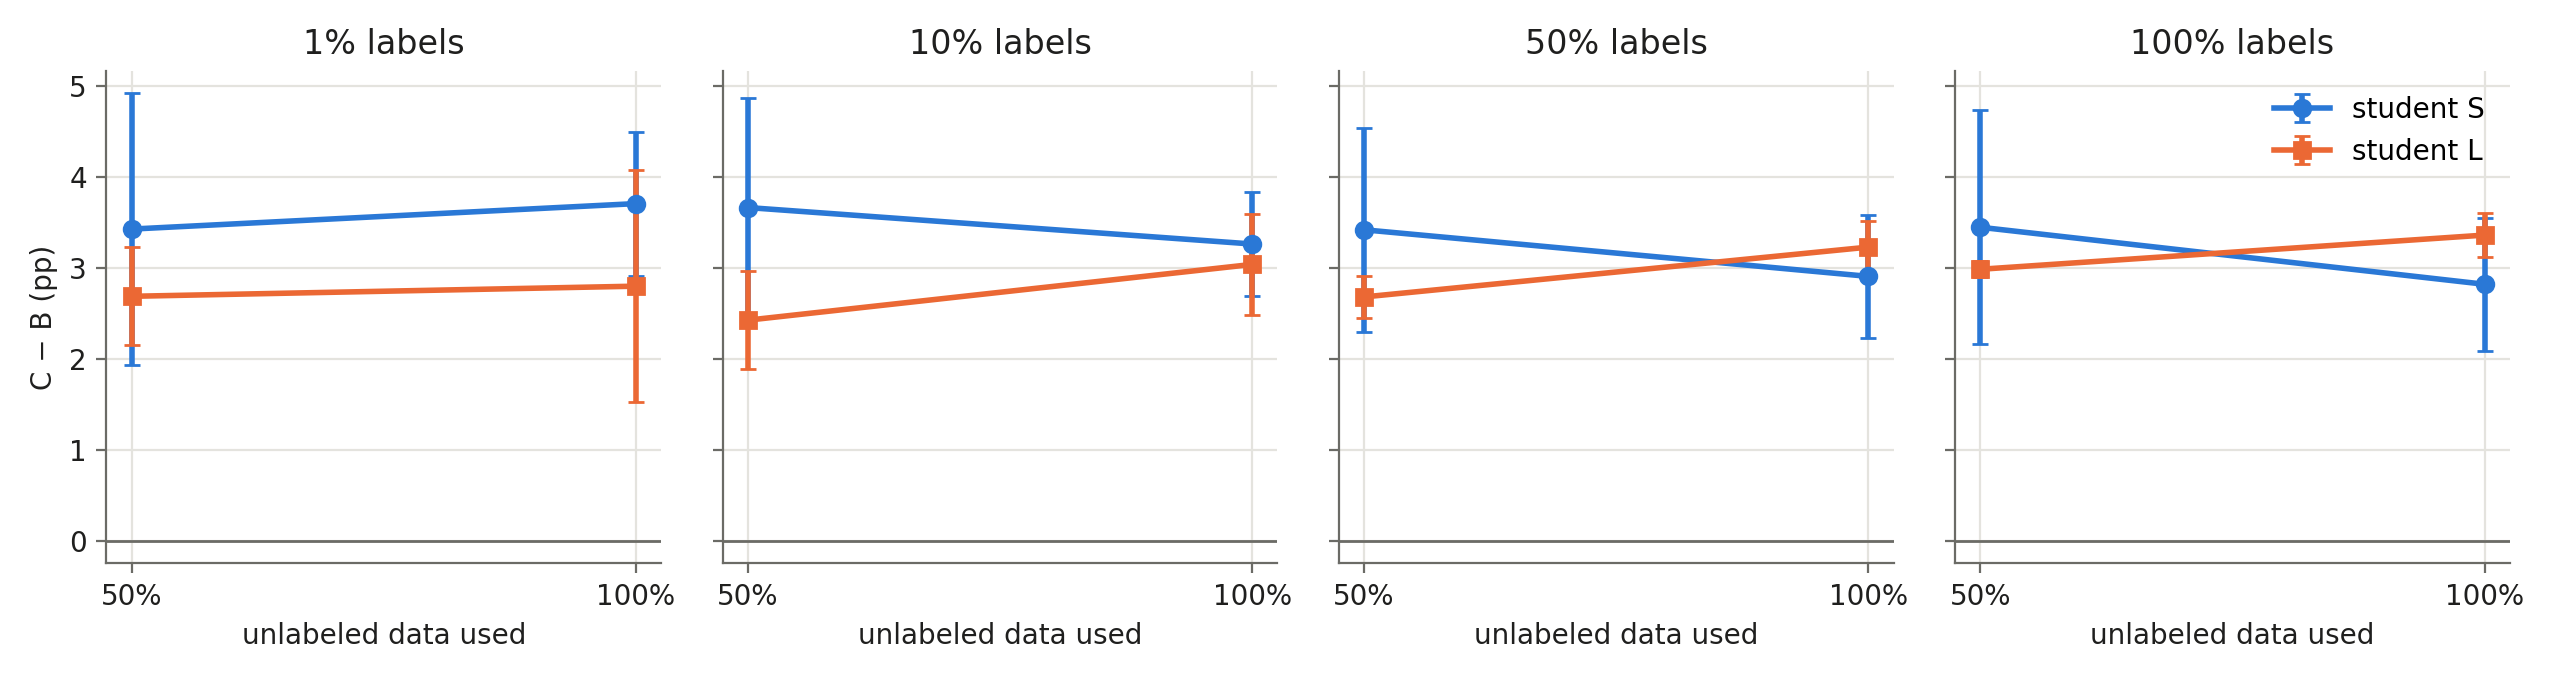

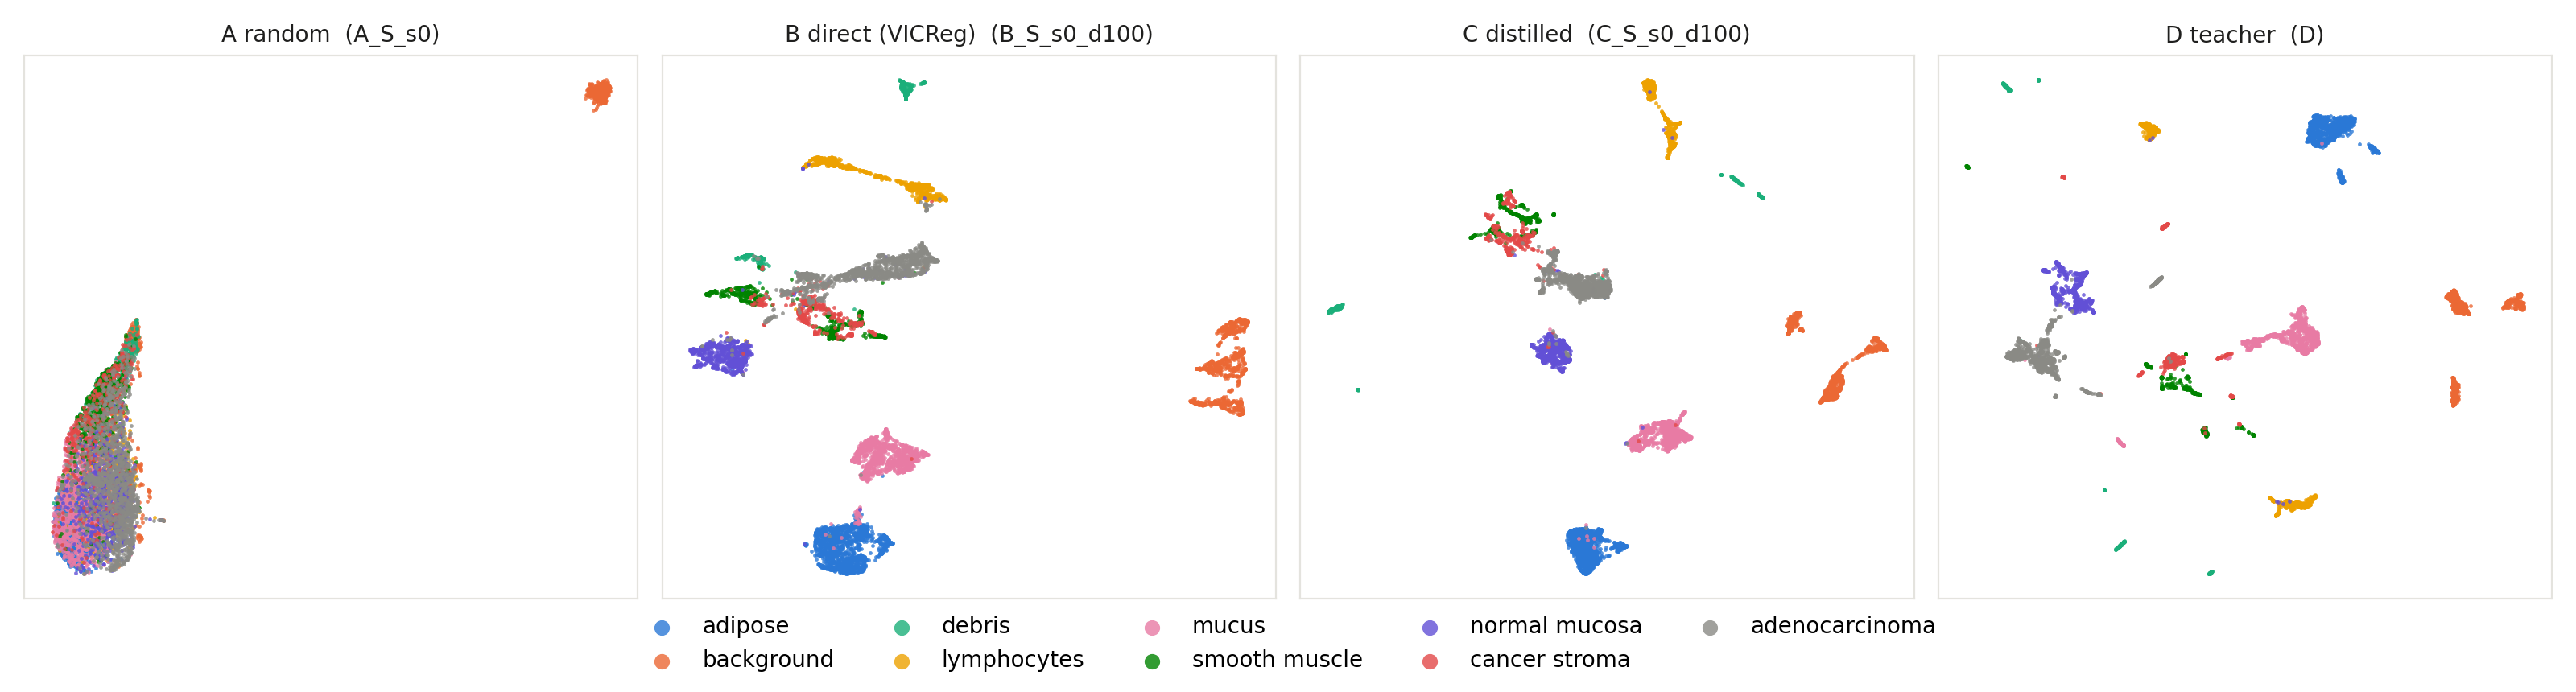

In [4]:
# relatório final: tabelas em results/, figuras em figures/
report("umap", "S")
print((C.RESULTS / "main_table.md").read_text())
for f in ["label_efficiency", "gap_vs_params", "ablation_gap", "projection_S"]:
    if (C.FIGS / f"{f}.png").exists():
        display(Image(str(C.FIGS / f"{f}.png")))